# Chapter 10 · The Black–Scholes equation by hedging: interactive demos

Companion to Chapter 10 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/10-delta-hedging.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Throughout, the stock is a geometric Brownian motion with drift $\mu$ under the real-world measure, the money
market grows at rate $r$, and a seller hedges a call with strike $K$ and maturity $T$ by holding
$\Delta=N(d_+)$ shares (Proposition 10.9), rebalanced at $n$ equally spaced dates.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider
from matplotlib.ticker import NullFormatter, ScalarFormatter

from ieor222.blackscholes import call, gbm_paths
from ieor222.hedging import (asymptotic_rms, call_delta, call_gamma, call_hedge, gamma_moment_call,
                             gamma_theta, hedged_pnl, hedging_error)
from ieor222.style import COBALT, GOLD, GREY, INK, use_style

use_style()
GREEN = "#1BAF7A"

## 1. The delta hedge along one path

Theorem 10.7 says that the portfolio that starts with the price $c(0,S_0)$ and holds $\partial_x c(t,S_t)$ shares
is worth $c(t,S_t)$ at every time, and pays $(S_T-K)^+$ at maturity. Below, the hedge is rebalanced at $n$ dates
only. The left panel shows the stock; the middle panel the number of shares, which moves towards $1$ or $0$ as the
call ends in or out of the money; the right panel the value of the hedge portfolio and the price of the call.
With many rebalancing dates the two curves are hard to tell apart.

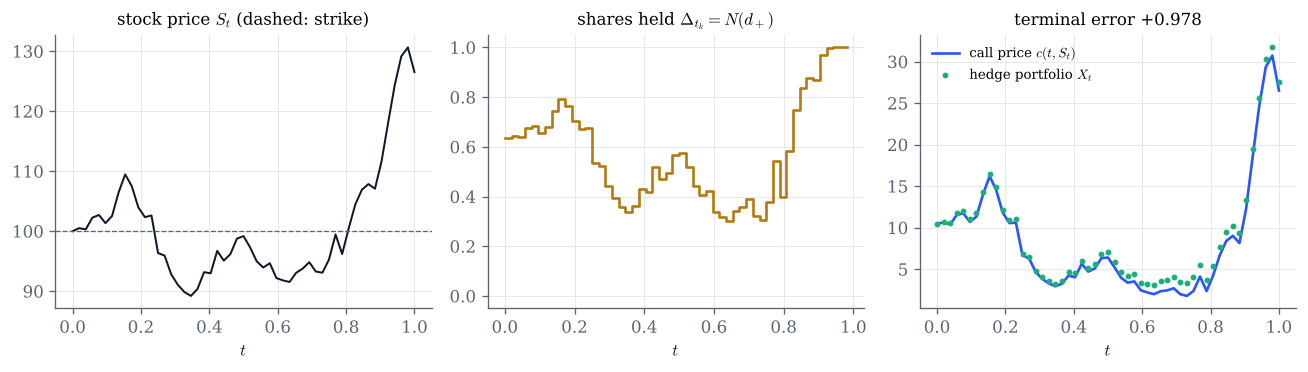

In [2]:
def one_path(n=52, mu=0.10, sigma=0.20, K=100.0, seed=0, S0=100.0, T=1.0, r=0.05):
    t, S = gbm_paths(S0, T, mu, sigma, n, 1, seed=seed)
    t, S = t, S[0]
    value = call(S, K, T - t, r, sigma)
    shares = call_delta(S[:-1], K, T - t[:-1], r, sigma)
    out = call_hedge(S0, K, T, r, sigma, mu, n, 1, seed=seed)
    X = out["wealth"][0]
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
    axes[0].plot(t, S, color=INK, lw=1.2)
    axes[0].axhline(K, color=GREY, lw=0.8, ls="--")
    axes[0].set(xlabel="$t$", title="stock price $S_t$ (dashed: strike)")
    axes[1].step(t[:-1], shares, where="post", color=GOLD)
    axes[1].set(xlabel="$t$", ylim=(-0.05, 1.05), title=r"shares held $\Delta_{t_k}=N(d_+)$")
    axes[2].plot(t, value, color=COBALT, label="call price $c(t,S_t)$")
    axes[2].plot(t, X, "o", ms=2.5, color=GREEN, label="hedge portfolio $X_t$")
    axes[2].set(xlabel="$t$", title=f"terminal error {X[-1] - max(S[-1] - K, 0):+.3f}")
    axes[2].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

one_path()

In [3]:
# Explore: more rebalancing dates make the portfolio stick to the price; the drift changes the path, not the hedge.
interact(one_path,
         n=IntSlider(value=52, min=2, max=1000, step=1, continuous_update=False, description="n"),
         mu=FloatSlider(value=0.10, min=-0.3, max=0.5, step=0.05, continuous_update=False, description="μ"),
         sigma=FloatSlider(value=0.20, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ"),
         K=FloatSlider(value=100.0, min=70.0, max=130.0, step=5.0, continuous_update=False, description="K"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## 2. The distribution of the hedging error

Over many paths, the terminal error $X^n_T-(S_T-K)^+$ is centred near zero and its spread shrinks as $n$ grows
(Proposition 10.11). The title compares the root-mean-square error with the prediction of the leading term (10.13): $e^{rT}$ times
$\sqrt{(\sigma^4h/2)\int_0^T E[e^{-2ru}\Gamma(u,S_u)^2S_u^4]\,du}$, with $h=T/n$. The call does not satisfy the
smoothness hypothesis (H) of the proposition, but the prediction still describes it (see the discussion after the
proposition in the notes).

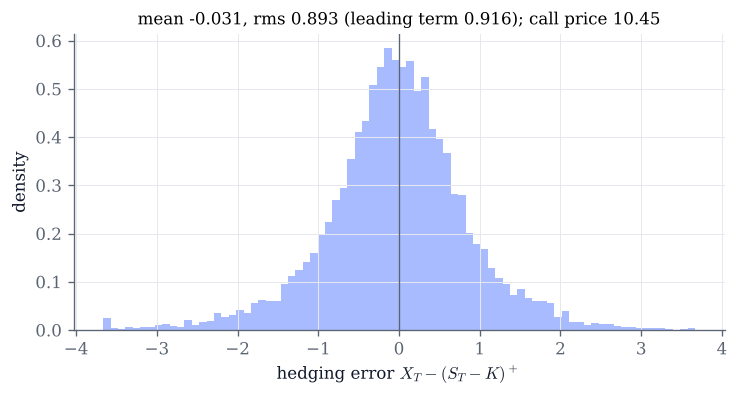

In [4]:
def error_histogram(n=52, mu=0.15, sigma=0.20, K=100.0, n_paths=10_000, S0=100.0, T=1.0, r=0.05):
    e = call_hedge(S0, K, T, r, sigma, mu, n, n_paths, seed=n)["error"]
    moment = lambda u: gamma_moment_call(u, S0, K, T, r, sigma, mu)
    lead = np.exp(r * T) * asymptotic_rms(moment, T, sigma, n)
    fig, ax = plt.subplots(figsize=(7, 3.2))
    lim = max(4 * lead, 1e-6)
    ax.hist(np.clip(e, -lim, lim), bins=80, density=True, color=COBALT, alpha=0.4)
    ax.axvline(0, color=GREY, lw=0.8)
    ax.set(xlabel="hedging error $X_T-(S_T-K)^+$", ylabel="density",
           title=f"mean {e.mean():+.3f}, rms {np.sqrt(np.mean(e**2)):.3f} (leading term {lead:.3f}); "
                 f"call price {call(S0, K, T, r, sigma):.2f}")
    plt.show()

error_histogram()

In [5]:
interact(error_histogram,
         n=IntSlider(value=52, min=2, max=500, continuous_update=False, description="n"),
         mu=FloatSlider(value=0.15, min=-0.3, max=0.5, step=0.05, continuous_update=False, description="μ"),
         sigma=FloatSlider(value=0.20, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ"),
         K=FloatSlider(value=100.0, min=70.0, max=130.0, step=5.0, continuous_update=False, description="K"),
         n_paths=IntSlider(value=10_000, min=1_000, max=40_000, step=1_000, continuous_update=False, description="paths"));

## 3. The rate: error $\approx$ constant $\times\,n^{-1/2}$

The root-mean-square error against the number of rebalancing dates, on log scales, for the drift you choose and for
$\mu=r$. Both lines have slope $-1/2$: to halve the error, rebalance four times as often. The drift moves the
constant only through the law of the path; it never enters the price or the hedge (Remark 10.6).

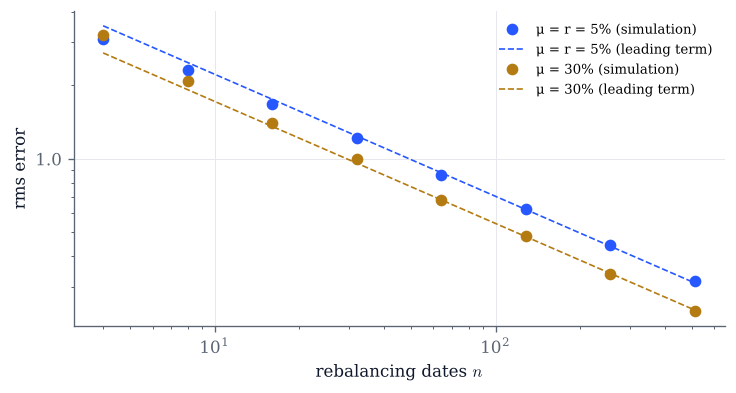

In [6]:
def rate(mu=0.30, sigma=0.20, K=100.0, n_paths=4_000, S0=100.0, T=1.0, r=0.05):
    ns = 2 ** np.arange(2, 10)
    value = lambda s, x: call(x, K, T - s, r, sigma)
    delta = lambda s, x: call_delta(x, K, T - s, r, sigma)
    payoff = lambda x: np.maximum(x - K, 0.0)
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for m, color, label in ((r, COBALT, f"μ = r = {r:.0%}"), (mu, GOLD, f"μ = {mu:.0%}")):
        t, S = gbm_paths(S0, T, m, sigma, ns[-1], n_paths, seed=7)
        rms = [np.sqrt(np.mean(hedging_error(t[::ns[-1] // n], S[:, ::ns[-1] // n], value, delta, payoff, r) ** 2))
               for n in ns]
        moment = lambda u, m=m: gamma_moment_call(u, S0, K, T, r, sigma, m)
        lead = [np.exp(r * T) * asymptotic_rms(moment, T, sigma, n) for n in ns]
        ax.plot(ns, rms, "o", color=color, label=label + " (simulation)")
        ax.plot(ns, lead, "--", color=color, lw=1, label=label + " (leading term)")
    ax.set(xscale="log", yscale="log", xlabel="rebalancing dates $n$", ylabel="rms error")
    ax.yaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.legend(fontsize=8)
    plt.show()

rate()

In [7]:
interact(rate,
         mu=FloatSlider(value=0.30, min=-0.3, max=0.6, step=0.05, continuous_update=False, description="μ"),
         sigma=FloatSlider(value=0.20, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ"),
         K=FloatSlider(value=100.0, min=60.0, max=140.0, step=5.0, continuous_update=False, description="K"),
         n_paths=IntSlider(value=4_000, min=1_000, max=10_000, step=1_000, continuous_update=False, description="paths"));

## 4. Theta pays for gamma

Over one period of length $h$, a delta-hedged *long* call gains about $\frac12\Gamma S^2R^2$ from the move $R$ of the
(discounted) stock and loses $\frac12\Gamma S^2\sigma^2h$ to time decay: the gamma–theta decomposition (10.12). It
breaks even when $|R|=\sigma\sqrt h$ (vertical lines). The right panel adds up these terms along many paths and
compares the sum with the actual hedging error of the seller: they lie close to the diagonal.

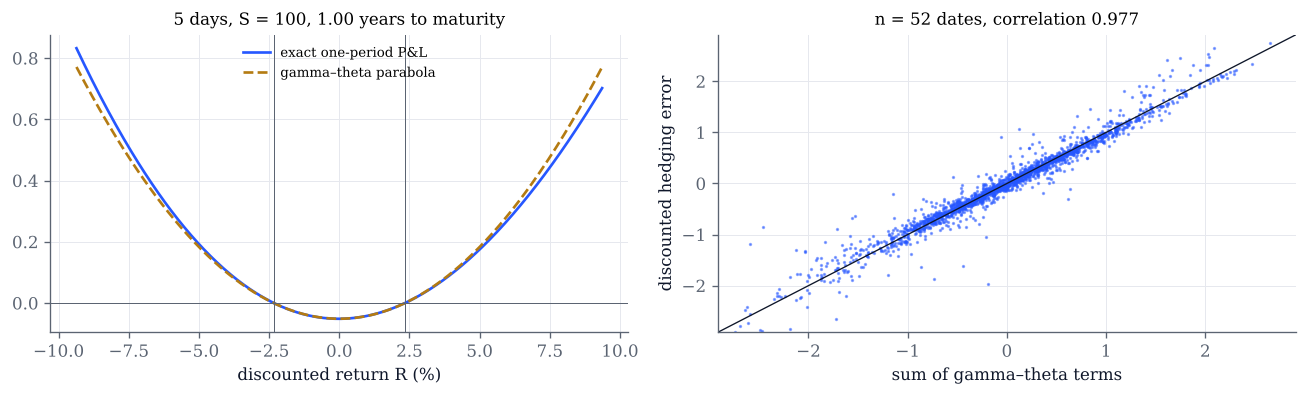

In [8]:
def gamma_theta_demo(days=5, spot=100.0, tau=1.0, n=52, sigma=0.20, mu=0.15, K=100.0, r=0.05):
    h = days / 365
    if h >= tau:
        print("the period must be shorter than the time to maturity"); return
    T = tau
    value = lambda s, x: call(x, K, T - s, r, sigma)
    delta = lambda s, x: call_delta(x, K, T - s, r, sigma)
    gamma = lambda s, x: call_gamma(x, K, T - s, r, sigma)
    R = np.linspace(-4 * sigma * np.sqrt(h), 4 * sigma * np.sqrt(h), 401)
    exact = np.exp(-r * h) * value(h, np.exp(r * h) * spot * (1 + R)) - value(0.0, spot) - delta(0.0, spot) * spot * R
    G = gamma(0.0, spot) * spot**2
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
    ax.plot(100 * R, exact, color=COBALT, label="exact one-period P&L")
    ax.plot(100 * R, 0.5 * G * (R**2 - sigma**2 * h), "--", color=GOLD, label="gamma–theta parabola")
    for side in (-1, 1):
        ax.axvline(100 * side * sigma * np.sqrt(h), color=GREY, lw=0.6)
    ax.axhline(0, color=GREY, lw=0.6)
    ax.set(xlabel="discounted return R (%)", title=f"{days} days, S = {spot:.0f}, {tau:.2f} years to maturity")
    ax.legend(fontsize=8)
    t, S = gbm_paths(spot, T, mu, sigma, n, 2_000, seed=3)
    err = -hedged_pnl(t, S, value, delta, r).sum(axis=1)
    lead = -gamma_theta(t, S, gamma, r, sigma).sum(axis=1)
    lim = np.quantile(np.abs(err), 0.995)
    ax2.plot(lead, err, ".", ms=2, color=COBALT, alpha=0.5)
    ax2.plot([-lim, lim], [-lim, lim], color=INK, lw=0.8)
    ax2.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="sum of gamma–theta terms",
            ylabel="discounted hedging error", title=f"n = {n} dates, correlation {np.corrcoef(lead, err)[0, 1]:.3f}")
    fig.tight_layout()
    plt.show()

gamma_theta_demo()

In [9]:
interact(gamma_theta_demo,
         days=IntSlider(value=5, min=1, max=60, continuous_update=False, description="days"),
         spot=FloatSlider(value=100.0, min=70.0, max=130.0, step=5.0, continuous_update=False, description="S"),
         tau=FloatSlider(value=1.0, min=0.1, max=2.0, step=0.1, continuous_update=False, description="τ"),
         n=IntSlider(value=52, min=4, max=400, continuous_update=False, description="n"),
         sigma=FloatSlider(value=0.20, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ"),
         mu=FloatSlider(value=0.15, min=-0.3, max=0.5, step=0.05, continuous_update=False, description="μ"));

## Things to try

- In section 1, set $n=2$ and then $n=1000$ with the same seed. Where along the path does the coarse hedge lose
  track of the price?
- In section 2, move the strike far out of the money. Why does the error shrink, relative to the price and in
  absolute terms? (Look at where the gamma is large.)
- In section 3, take $\mu$ very large or very negative. The constant changes but the slope does not. Can you
  explain the direction of the change?
- In section 4, shorten the time to maturity with the stock at the strike. What happens to the parabola, and
  why is the last week of an at-the-money option the hardest to hedge?